## Simulação de reunião

##### Frases longas que simulam uma reunião com retorno ao primeiro assunto

In [7]:
import numpy as np
from sentence_transformers import SentenceTransformer


sentences = [
    "Pessoal, acho que a gente precisa começar revisando o cronograma com um pouco mais de cuidado, porque olhando para a última entrega ficou bem claro que o atraso foi maior do que a gente tinha antecipado inicialmente.",
    "Se a gente não ajustar essas datas agora, considerando o que já aconteceu, é bem provável que todo o restante do planejamento acabe sendo impactado em cadeia nas próximas semanas.",

    "Mas antes de mexer diretamente no cronograma, talvez faça sentido a gente dar um passo atrás e entender melhor quais dessas tarefas realmente são prioritárias para essa primeira entrega.",
    "Porque, sendo bem realista, nem tudo que está planejado hoje precisa necessariamente entrar na primeira versão do produto.",
    "Se a gente conseguir focar no essencial, no que realmente gera valor imediato, a tendência é que a gente consiga entregar mais rápido e com menos risco.",

    "Só que tem um outro ponto que a gente não pode ignorar, que é a questão do orçamento, porque qualquer ajuste no tempo de desenvolvimento vai acabar refletindo diretamente em custo.",
    "Se a gente estender o prazo ou precisar de mais esforço do time, inevitavelmente esse custo vai subir, e isso já começa a pressionar o que foi aprovado inicialmente.",
    "Inclusive, o pessoal do financeiro já comentou com a gente que não existe muita margem para aumento, então a gente precisa tomar cuidado com isso.",

    "Diante disso, acho que fica ainda mais importante a gente alinhar muito bem essa situação com os stakeholders, principalmente em relação às expectativas.",
    "Eles precisam entender não só que houve um atraso, mas também quais são os impactos reais disso e quais decisões a gente está tomando a partir daqui.",
    "Se essa comunicação não for feita de forma clara e estruturada, existe um risco grande de gerar desalinhamento ou até perda de confiança.",

    "Mas enfim, voltando para o cronograma em si, eu acho que agora, com tudo isso que a gente discutiu, faz sentido a gente repensar completamente as datas ao invés de tentar só ajustar pontualmente.",
    "Talvez seja mais seguro a gente construir um novo planejamento baseado no cenário atual, em vez de continuar adaptando o que já não está mais refletindo a realidade.",
    "Se a gente reorganizar o cronograma agora de forma mais realista, considerando prioridades e limitações de orçamento, a gente aumenta bastante a chance de evitar novos atrasos lá na frente."
]
sentences_e5 = [f"passage: {s}" for s in sentences]
model = SentenceTransformer('intfloat/multilingual-e5-base')

S = model.encode(sentences_e5)

print("\nEmbeddings (S):")
print(S.shape)
print(S)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3865.04it/s]
XLMRobertaModel LOAD REPORT from: intfloat/multilingual-e5-base
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Embeddings (S):
(14, 768)
[[ 0.01683192  0.03491735 -0.01964989 ... -0.0342239  -0.0214838
   0.03700225]
 [ 0.0295227   0.03992894 -0.03014433 ... -0.04185752 -0.03090021
   0.03172306]
 [ 0.02384199  0.03494973 -0.04438496 ... -0.04084978 -0.01014175
   0.0255723 ]
 ...
 [ 0.02438871  0.02692666 -0.03615847 ... -0.02316502 -0.01773289
   0.02542305]
 [ 0.03720478  0.04936574 -0.02381814 ... -0.0236755  -0.02558716
   0.03317825]
 [ 0.01836267  0.0315499  -0.03860434 ... -0.04147097 -0.03205267
   0.03610655]]


In [8]:
from sklearn.metrics.pairwise import cosine_similarity

scores = cosine_similarity(S)

n = len(sentences_e5)
A = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        if j < i: 
            A[i, j] = scores[i, j]

print(A)

[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.        ]
 [0.95687133 0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.        ]
 [0.95249808 0.94188273 0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.        ]
 [0.92632771 0.93758154 0.93417466 0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.        ]
 [0.94619894 0.95730281 0.93259501 0.93021119 0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.        ]
 [0.94936693 0.96124029 0.95097637 0.94787276 0.94199902 0.
  0.         0.         0.         0.         0.         0.
  0.         0.        ]
 [0.95852309 0.9723047  0.9402265  0.933429   0.96127814 0.95986891
  0.         0.         0.         0.         0.         0.
  

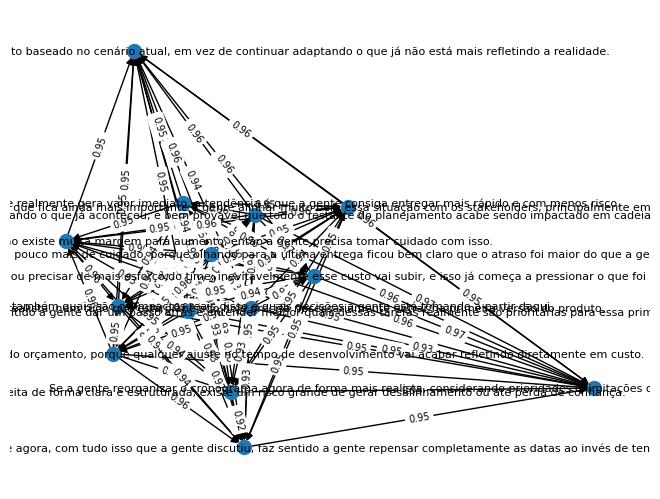

In [9]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

for i, s in enumerate(sentences_e5):
    G.add_node(i, label=s)

for i in range(n):
    for j in range(n):
        weight = A[i, j]
        if weight > 0.2:
            G.add_edge(j, i, weight=weight)

pos = nx.spring_layout(G)

nx.draw(G, pos, node_size=100)

node_labels = {i: s for i, s in enumerate(sentences)}
nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=8)

edge_labels = {k: round(v, 2) for k, v in nx.get_edge_attributes(G, 'weight').items()}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

plt.show()

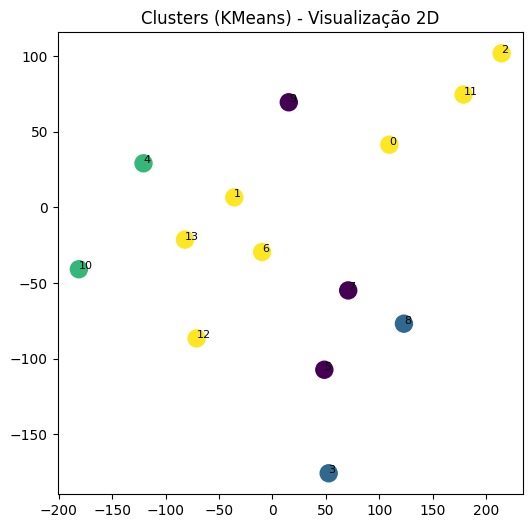

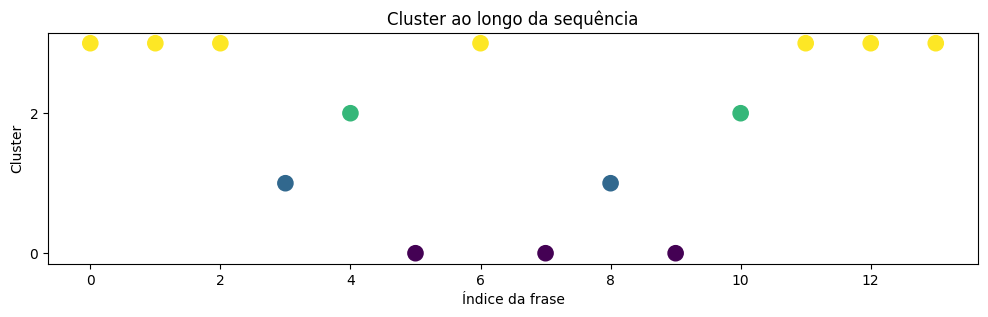

In [10]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.preprocessing import normalize

S_norm = normalize(S)

kmeans = KMeans(n_clusters=4, random_state=0)
labels = kmeans.fit_predict(S_norm)

tsne = TSNE(n_components=2, random_state=0, perplexity=5)
S_2d = tsne.fit_transform(S_norm)


plt.figure(figsize=(6,6))
plt.scatter(S_2d[:,0], S_2d[:,1], c=labels, s=150)

for i in range(len(sentences)):
    plt.text(S_2d[i,0], S_2d[i,1], str(i), fontsize=8)

plt.title("Clusters (KMeans) - Visualização 2D")
plt.show()

plt.figure(figsize=(12,3))
plt.scatter(range(len(sentences)), labels, c=labels, s=120)

plt.yticks([0,2])
plt.xlabel("Índice da frase")
plt.ylabel("Cluster")
plt.title("Cluster ao longo da sequência")

plt.show()

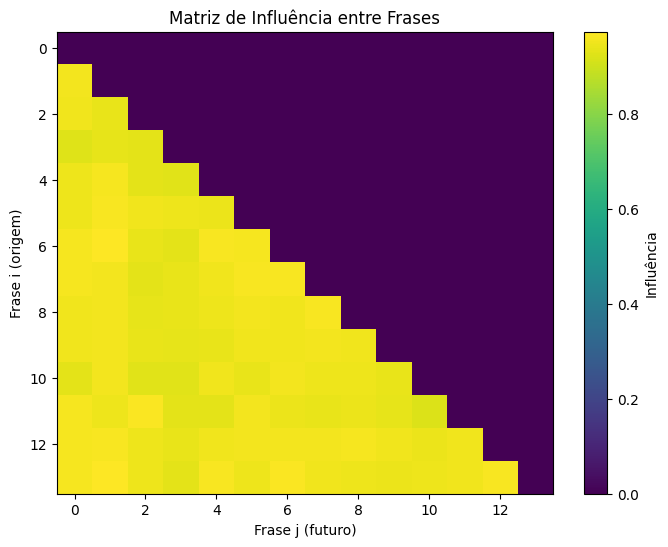

In [11]:
plt.figure(figsize=(8,6))
plt.imshow(A, cmap="viridis", aspect="auto")
plt.colorbar(label="Influência")
plt.title("Matriz de Influência entre Frases")
plt.xlabel("Frase j (futuro)")
plt.ylabel("Frase i (origem)")
plt.show()


 Segmentos detectados:


--- Segmento 1 (0 → 2) ---
- Pessoal, acho que a gente precisa começar revisando o cronograma com um pouco mais de cuidado, porque olhando para a última entrega ficou bem claro que o atraso foi maior do que a gente tinha antecipado inicialmente.
- Se a gente não ajustar essas datas agora, considerando o que já aconteceu, é bem provável que todo o restante do planejamento acabe sendo impactado em cadeia nas próximas semanas.
- Mas antes de mexer diretamente no cronograma, talvez faça sentido a gente dar um passo atrás e entender melhor quais dessas tarefas realmente são prioritárias para essa primeira entrega.

--- Segmento 2 (3 → 9) ---
- Porque, sendo bem realista, nem tudo que está planejado hoje precisa necessariamente entrar na primeira versão do produto.
- Se a gente conseguir focar no essencial, no que realmente gera valor imediato, a tendência é que a gente consiga entregar mais rápido e com menos risco.
- Só que tem um outro ponto que a gente não pode 

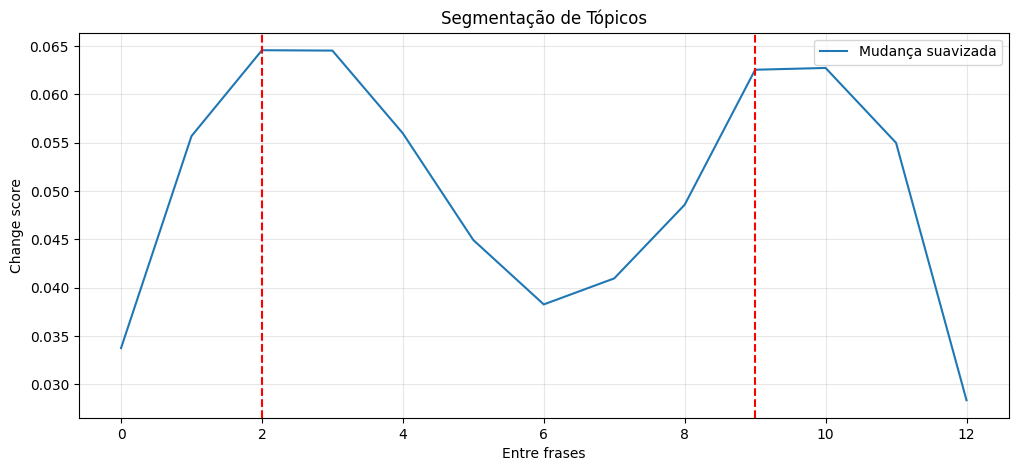

In [14]:
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity

S_norm = normalize(S)
n = len(S_norm)

adj_sim = np.array([
    cosine_similarity(S_norm[i].reshape(1, -1), S_norm[i+1].reshape(1, -1))[0, 0]
    for i in range(n - 1)
])

change = 1 - adj_sim

window = 3
kernel = np.ones(window) / window
change_smooth = np.convolve(change, kernel, mode='same')

threshold = np.mean(change_smooth) + 0.87 * np.std(change_smooth)

split_points = np.where(change_smooth > threshold)[0]

min_distance = 2
filtered_splits = []

for idx in split_points:
    if not filtered_splits or idx - filtered_splits[-1] > min_distance:
        filtered_splits.append(idx)

split_points = filtered_splits

segments = []
start = 0

for idx in split_points:
    segments.append((start, idx+1))
    start = idx+1

segments.append((start, n))

print("\n Segmentos detectados:\n")

for i, (s, e) in enumerate(segments):
    print(f"\n--- Segmento {i+1} ({s} → {e-1}) ---")
    for sent in sentences[s:e]:
        print("-", sent)


print("\n Rótulos dos segmentos:\n")

for i, (s, e) in enumerate(segments):
    mid = (s + e) // 2
    print(f"Segmento {i+1}: {sentences[mid]}")


plt.figure(figsize=(12,5))

plt.plot(change_smooth, label="Mudança suavizada")

for idx in split_points:
    plt.axvline(idx, color='red', linestyle='--')

plt.title("Segmentação de Tópicos")
plt.xlabel("Entre frases")
plt.ylabel("Change score")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

O modelo não separa os tópicos esperados pois todos pertencem ao mesmo domínio semântico. As mudanças observadas são estruturais e não representam uma ruptura significativa no espaço de embeddings.